In [72]:
import pandas as pd
import numpy as np

df = pd.read_csv("dataset.csv")

df.head()

,id,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,1,40.5,18.9,180.0,3950.0
1,2,49.4,15.8,216.0,4925.0
2,3,36.2,16.1,187.0,3550.0
3,4,51.5,18.7,187.0,3250.0
4,5,37.6,17.0,185.0,3600.0


In [73]:
#outlier filter
fl = df["flipper_length_mm"]
df.loc[(fl < 150) | (fl > 250), "flipper_length_mm"] = fl[(fl >= 150) & (fl <= 250)].median()

feats = [col for col in df.columns if col != 'id']
X = df[feats]

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=feats)

X.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,0.305455,0.690476,0.135593,0.347222
1,0.629091,0.321429,0.745763,0.618056
2,0.149091,0.357143,0.254237,0.236111
3,0.705455,0.666667,0.254237,0.152778
4,0.200000,0.464286,0.220339,0.250000


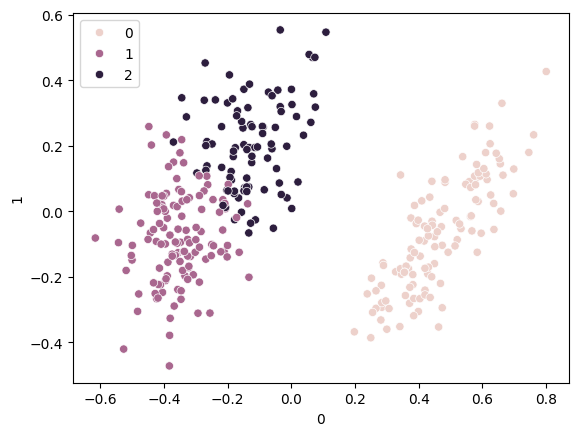

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

decom = PCA(n_components=2, random_state=42)
X_red = pd.DataFrame(decom.fit_transform(X))

model = KMeans(n_clusters=3, random_state=42)
labels = model.fit_predict(X)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [75]:
X["species"] = labels

X.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,0.305455,0.690476,0.135593,0.347222,1
1,0.629091,0.321429,0.745763,0.618056,0
2,0.149091,0.357143,0.254237,0.236111,1
3,0.705455,0.666667,0.254237,0.152778,2
4,0.200000,0.464286,0.220339,0.250000,1


In [76]:
#acum gen despartim sexul per species

preds = np.empty(len(X), dtype=object)
for s in range(3):
    mask = (X.species == s)
    Xs = X.loc[mask, feats]
    pred = KMeans(n_clusters=2, random_state=42).fit_predict(Xs)
    preds[mask] = np.where(pred == 1, "MALE", "FEMALE")

preds[:5]

array(['MALE', 'MALE', 'FEMALE', 'FEMALE', 'FEMALE'], dtype=object)

In [77]:
submission = pd.DataFrame({
    "id": df['id'],
    "sex": preds
})

submission

,id,sex
0,1,MALE
1,2,MALE
2,3,FEMALE
3,4,FEMALE
4,5,FEMALE
...,...,...
329,330,MALE
330,331,FEMALE
331,332,MALE
332,333,FEMALE


In [78]:
submission.sex.value_counts()

sex
FEMALE    171
MALE      163
Name: count, dtype: int64

In [79]:
submission.to_csv("submission.csv", index=False)